In [ ]:
Selected Data and Why I Chose It

For this assignment, I chose to analyze Alice's Adventures in Wonderland by Lewis Carroll using a text file from Project Gutenberg. I wanted to see how I could take something like a book, which isn't traditionally organized into rows and columns, and use PySpark to identify patterns within it. I always try to connect what I'm learning in class to what I might encounter in the workplace, and I thought this would be a good introduction to working with unstructured text.

In [1]:
%pip install pyspark

Note: you may need to restart the kernel to use updated packages.


In [1]:
import os
import sys
import subprocess

python_exe = sys.executable

os.environ["JAVA_HOME"] = (
    r"C:\Program Files\Eclipse Adoptium\jdk-17.0.20.101-hotspot"
)
os.environ["PATH"] = (
    os.path.join(os.environ["JAVA_HOME"], "bin")
    + os.pathsep + os.environ["PATH"]
)

os.environ["PYSPARK_PYTHON"] = python_exe
os.environ["PYSPARK_DRIVER_PYTHON"] = python_exe

print("Jupyter Python:", python_exe)
print("Python version:", sys.version.split()[0])

from pyspark import SparkConf, SparkContext

conf = (
    SparkConf()
    .setMaster("local[1]")
    .setAppName("WonderlandWordAnalysis")
    .set("spark.pyspark.python", python_exe)
    .set("spark.pyspark.driver.python", python_exe)
)

sc = SparkContext(conf=conf)

# Explicitly set the executable used for Python RDD workers
sc.pythonExec = python_exe

print("Spark worker executable:", sc.pythonExec)

Jupyter Python: C:\Users\wsher\anaconda3\python.exe
Python version: 3.13.9
Spark worker executable: C:\Users\wsher\anaconda3\python.exe


In [2]:
numbers = sc.parallelize([1, 2, 3, 4, 5], 1)

print("Count:", numbers.count())
print("First:", numbers.first())
print("Sum:", numbers.sum())

Count: 5
First: 1
Sum: 15


In [3]:
import urllib.request
from pathlib import Path

book_path = Path("alice_in_wonderland.txt")

if not book_path.exists():
    urllib.request.urlretrieve(
        "https://www.gutenberg.org/files/11/11-0.txt",
        book_path
    )

book_rdd = sc.textFile(str(book_path.resolve()))

print("Total lines:", book_rdd.count())
print("Sample lines:", book_rdd.take(5))

Total lines: 3384
Sample lines: ['*** START OF THE PROJECT GUTENBERG EBOOK 11 ***', '', '[Illustration]', '', '']


In [ ]:
Step 2 perform MapReduce word counting

In [4]:
import re

words_rdd = (
    book_rdd
    .flatMap(lambda line: re.findall(r"[a-z]+", line.lower()))
)

word_counts = (
    words_rdd
    .map(lambda word: (word, 1))
    .reduceByKey(lambda a, b: a + b)
)

top_20 = word_counts.takeOrdered(
    20, key=lambda x: -x[1]
)

print("Total words:", words_rdd.count())
print("Unique words:", word_counts.count())

for word, count in top_20:
    print(f"{word}: {count}")

Total words: 27439
Unique words: 2579
the: 1653
and: 874
to: 729
a: 637
it: 595
she: 553
i: 546
of: 517
said: 462
you: 411
alice: 399
in: 370
was: 357
that: 315
as: 263
her: 248
t: 218
at: 212
s: 204
on: 193


In [ ]:
RDD, MapReduce, and the 3 Vs of Big Data

I used PySpark's RDDs and MapReduce operations to process the book and calculate word frequencies. I started with flatMap() to separate the text into individual words, used map() to assign each word a count of one, and then used reduceByKey() to add up how many times each word appeared.

Volume: My dataset contained 3,384 lines and 27,439 words. While this is a relatively small dataset, RDDs can distribute larger amounts of data across multiple partitions, making it possible to process much larger collections of text. I could see this being useful for organizations that need to analyze thousands of documents instead of manually reviewing them one by one.

Velocity: Since I was working with a book, the data wasn't constantly changing or coming in through a live stream. However, MapReduce allowed me to process the existing data in batches, and a similar approach could be used to process newly arriving batches of documents. This reminded me of how organizations regularly update policies, procedures, and technical documentation.

Variety: The book was originally unstructured text, so I couldn't analyze it the same way I would a spreadsheet or database table. Using RDD transformations, I was able to turn the text into structured word-frequency pairs that I could organize, compare, and visualize.

In [ ]:
Step 3: Visualize your results

,Word,Frequency
0,the,1653
1,and,874
2,to,729
3,a,637
4,it,595
5,she,553
6,i,546
7,of,517
8,said,462
9,you,411


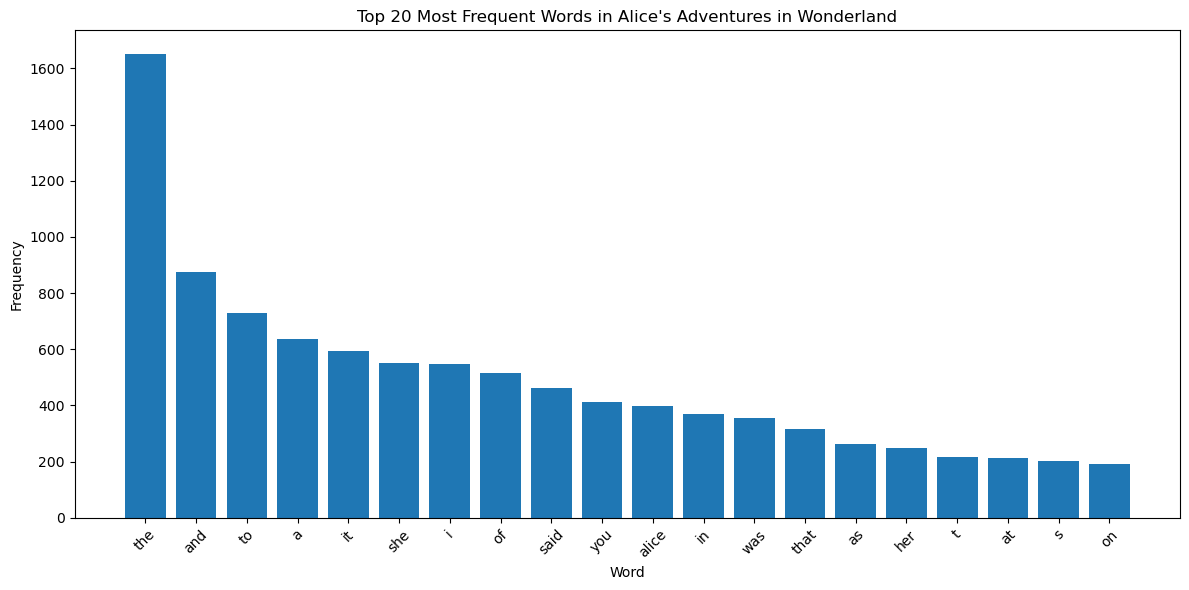

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame(top_20, columns=["Word", "Frequency"])

display(df)

plt.figure(figsize=(12, 6))
plt.bar(df["Word"], df["Frequency"])
plt.title("Top 20 Most Frequent Words in Alice's Adventures in Wonderland")
plt.xlabel("Word")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
improve analysis

,Word,Frequency
0,said,462
1,alice,399
2,all,182
3,had,178
4,so,152
5,very,144
6,what,141
7,this,134
8,little,129
9,out,117


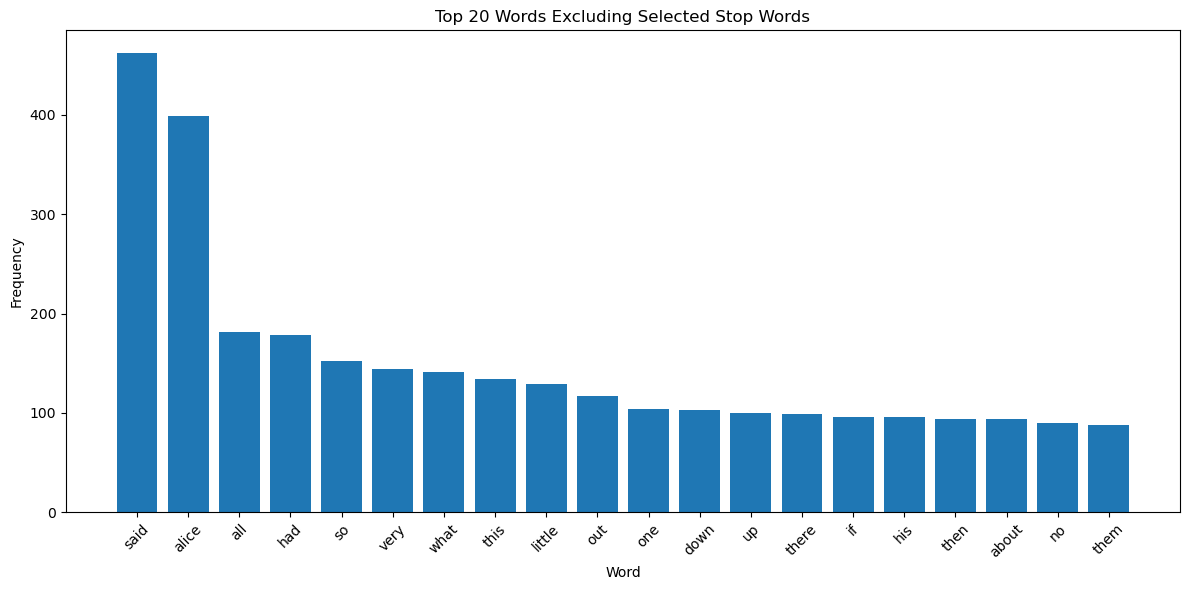

In [6]:
stop_words = {
    "the", "and", "to", "a", "it", "she", "i",
    "of", "you", "in", "was", "that", "as",
    "her", "at", "on", "is", "for", "with",
    "he", "they", "but", "not", "be", "t", "s"
}

meaningful_words = (
    word_counts
    .filter(lambda pair: pair[0] not in stop_words)
    .takeOrdered(20, key=lambda x: -x[1])
)

meaningful_df = pd.DataFrame(
    meaningful_words,
    columns=["Word", "Frequency"]
)

display(meaningful_df)

plt.figure(figsize=(12, 6))
plt.bar(meaningful_df["Word"], meaningful_df["Frequency"])
plt.title("Top 20 Words Excluding Selected Stop Words")
plt.xlabel("Word")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
Step 4: Calculate summary statistics

In [7]:
# Calculate overall text statistics

total_lines = book_rdd.count()
total_words = words_rdd.count()
unique_words = word_counts.count()

# Find the longest words
longest_words = (
    word_counts
    .sortBy(lambda x: len(x[0]), ascending=False)
    .take(10)
)

print("BOOK ANALYSIS SUMMARY")
print("----------------------")
print("Total lines:", total_lines)
print("Total words:", total_words)
print("Unique words:", unique_words)

print("\n10 Longest Words:")
for word, count in longest_words:
    print(f"{word}: {len(word)} letters, {count} occurrences")

BOOK ANALYSIS SUMMARY
----------------------
Total lines: 3384
Total words: 27439
Unique words: 2579

10 Longest Words:
disappointment: 14 letters, 1 occurrences
multiplication: 14 letters, 1 occurrences
contemptuously: 14 letters, 2 occurrences
affectionately: 14 letters, 1 occurrences
conversations: 13 letters, 2 occurrences
inquisitively: 13 letters, 1 occurrences
uncomfortable: 13 letters, 4 occurrences
circumstances: 13 letters, 1 occurrences
extraordinary: 13 letters, 2 occurrences
straightening: 13 letters, 1 occurrences


In [ ]:
Step 5: Create a comparison visualization

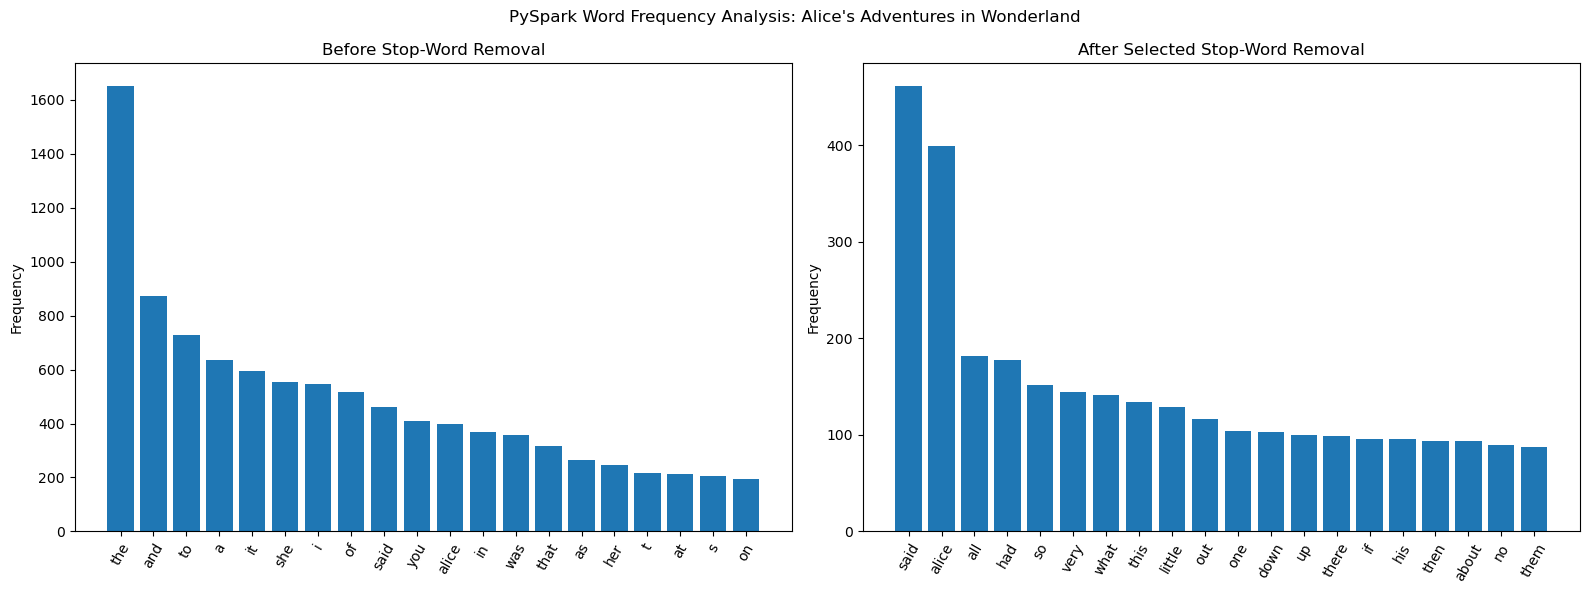

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].bar(df["Word"], df["Frequency"])
axes[0].set_title("Before Stop-Word Removal")
axes[0].tick_params(axis="x", rotation=60)
axes[0].set_ylabel("Frequency")

axes[1].bar(meaningful_df["Word"], meaningful_df["Frequency"])
axes[1].set_title("After Selected Stop-Word Removal")
axes[1].tick_params(axis="x", rotation=60)
axes[1].set_ylabel("Frequency")

plt.suptitle("PySpark Word Frequency Analysis: Alice's Adventures in Wonderland")
plt.tight_layout()
plt.show()

In [ ]:
Findings

After running my analysis, I found that the book contained 3,384 lines, 27,439 words, and 2,579 unique words. My first word-frequency analysis showed that "the" appeared 1,653 times, followed by "and" with 874 occurrences and "to" with 729 occurrences. I wasn't too surprised by those results because those are words we use constantly in English. After removing selected stop words, the results became more interesting. "Said" appeared 462 times, "alice" appeared 399 times, and "all" appeared 182 times. I also looked at the longest words in the book and found that "disappointment," "multiplication," "contemptuously," and "affectionately" were all 14 letters long, although most of them only appeared once.

In [ ]:
Interpretation

One of my biggest takeaways from the results was that just because the code runs correctly doesn't necessarily mean the information is useful. My first analysis was dominated by common words like "the" and "and," which didn't really tell me anything about the story. However, once I removed selected stop words, I started seeing words like "said" and "alice," which suggested that dialogue and the main character were a major focus throughout the book. I also noticed that words like "all" and "had" were still showing up, which made me realize that my stop-word list could have been more comprehensive. Looking back, I think this is a good example of why preprocessing matters when working with data. In my current work, I've learned that having data available is one thing, but making sure it's organized in a way that supports meaningful analysis is something completely different.

In [ ]:
Challenges and Troubleshooting

Before I could even begin analyzing the book, I ran into several issues trying to get PySpark working in my local Jupyter Notebook environment. I initially thought I would be able to install PySpark and start working on the assignment, but it turned into a much longer troubleshooting process than I expected. First, I received an error because PySpark wasn't installed, and after installing it, I started getting Java gateway errors. I eventually found out that Java wasn't being recognized by my environment, so I had to install Java 17 and configure the correct installation path.

After getting Java to work, I thought I was finally ready to start the assignment, but I ran into another error when I tried running a simple RDD operation. This time, the problem was that my Python worker was using version 3.11 while my Jupyter Notebook was using version 3.13. PySpark couldn't process the data because the two Python versions didn't match. I had to restart my kernel, update my environment settings, and explicitly configure Spark to use the correct Python executable. Once I finally got the output showing a count of five and a sum of fifteen from my test dataset, I knew I could move forward with the actual analysis.

Looking back, I think I spent more time getting my environment configured than I did analyzing the book itself. However, I also think this was one of the more useful parts of the assignment because troubleshooting is something I encounter when working in technology. Sometimes the biggest challenge isn't writing the code but figuring out why the tools aren't communicating with each other the way they're supposed to.

In [ ]:
Conclusion

This assignment helped me better understand how PySpark can be used to process unstructured data, and although I spent a good amount of time troubleshooting my environment, I learned just as much from resolving those issues as I did from the analysis itself. I could see similar techniques being useful in IT governance, particularly when analyzing large collections of policies, procedures, or compliance documentation to identify recurring terminology and patterns.

